# 03 Exploratory Analysis

**Objective:** describe the cleaned data: the distribution of `avg_daily_rate`, listings by neighbourhood and room type, missing data, outliers, and records by year. Each chart has a short interpretation.

**Data:** `data/processed/past_rates_clean.parquet`, produced by notebook 02. Nothing is removed here; this notebook only describes.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = PROJECT_ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "past_rates_clean.parquet")
print("Rows:", len(df), "| Listings:", df["listing_id"].nunique(), "| Columns:", df.shape[1])
print("Rows usable for spatial analysis:", int(df["use_in_spatial"].sum()))

Rows: 150034 | Listings: 4266 | Columns: 31
Rows usable for spatial analysis: 148576


## 1. Distribution and summary statistics of `avg_daily_rate`
Summary statistics are calculated on all 150,034 listing-month records. The histogram is shown on a normal and a log scale because the distribution is expected to be right-skewed. The median is used as the main measure of the typical rate.

In [2]:
r = df["avg_daily_rate"]
stats = r.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2)
stats["skewness"] = round(r.skew(), 2)
print(stats.to_string())

count       150034.00
mean           188.27
std            190.84
min             15.00
5%              45.20
25%             83.50
50%            140.60
75%            225.90
95%            476.44
99%            950.87
max           4983.10
skewness         5.42


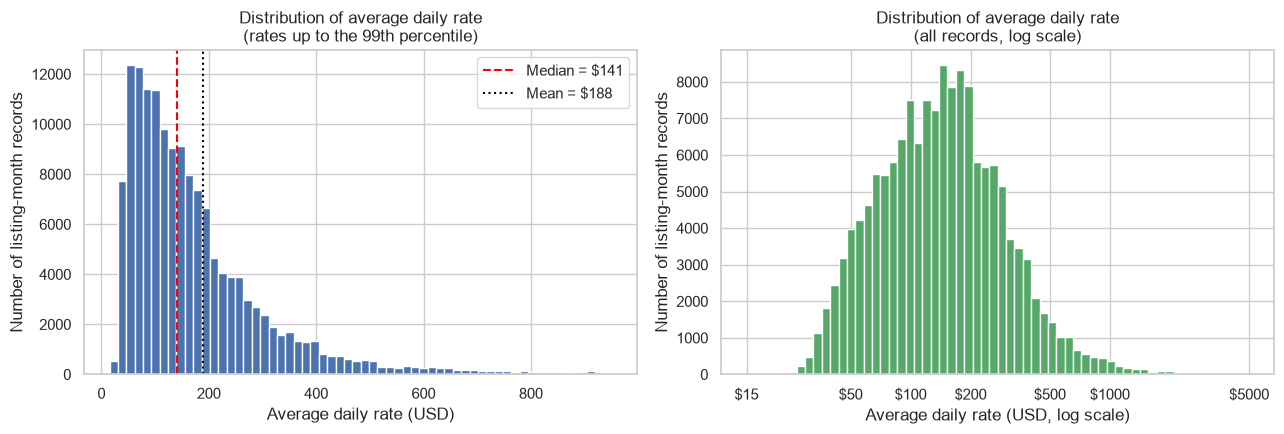

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: normal scale, cut at the 99th percentile so the shape is visible
cap = r.quantile(0.99)
axes[0].hist(r[r <= cap], bins=60, color="#4C72B0", edgecolor="white")
axes[0].axvline(r.median(), color="red", linestyle="--", label=f"Median = ${r.median():.0f}")
axes[0].axvline(r.mean(), color="black", linestyle=":", label=f"Mean = ${r.mean():.0f}")
axes[0].set_title("Distribution of average daily rate\n(rates up to the 99th percentile)")
axes[0].set_xlabel("Average daily rate (USD)")
axes[0].set_ylabel("Number of listing-month records")
axes[0].legend()

# Right: all data on a log scale
axes[1].hist(np.log10(r), bins=60, color="#55A868", edgecolor="white")
ticks = [15, 50, 100, 200, 500, 1000, 5000]
axes[1].set_xticks(np.log10(ticks))
axes[1].set_xticklabels([f"${t}" for t in ticks])
axes[1].set_title("Distribution of average daily rate\n(all records, log scale)")
axes[1].set_xlabel("Average daily rate (USD, log scale)")
axes[1].set_ylabel("Number of listing-month records")

plt.tight_layout()
plt.savefig(FIG / "03_rate_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Listings by neighbourhood and rates by room type
Listings per 2020 NTA (residential NTAs, spatial-analysis rows only) show how evenly the data covers the city. Rates by room type are shown on a log scale because of the skew.

Residential NTAs with at least 1 listing: 191 of 197
count    191.0
mean      22.1
std       29.5
min        1.0
25%        4.0
50%        9.0
75%       28.0
max      164.0

               NTAs  listings  median
boroname                             
Bronx            35       160     3.0
Brooklyn         52      1543    17.0
Manhattan        32      1752    49.5
Queens           58       721     8.5
Staten Island    14        45     2.5


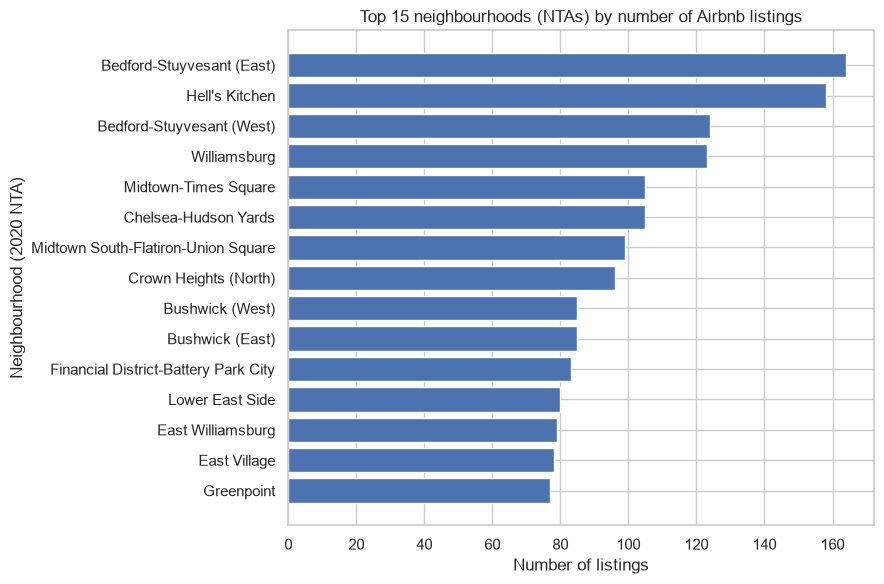

In [4]:
sp = df[df["use_in_spatial"]]
per_nta = sp.drop_duplicates("listing_id").groupby(["nta2020", "ntaname", "boroname"]).size().rename("listings").reset_index()

print("Residential NTAs with at least 1 listing:", len(per_nta), "of 197")
print(per_nta["listings"].describe().round(1).to_string())
print()
print(per_nta.groupby("boroname")["listings"].agg(["count", "sum", "median"]).rename(columns={"count": "NTAs", "sum": "listings"}).to_string())

top = per_nta.nlargest(15, "listings").sort_values("listings")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["ntaname"], top["listings"], color="#4C72B0")
ax.set_title("Top 15 neighbourhoods (NTAs) by number of Airbnb listings")
ax.set_xlabel("Number of listings")
ax.set_ylabel("Neighbourhood (2020 NTA)")
plt.tight_layout()
plt.savefig(FIG / "03_listings_by_nta.png", dpi=150, bbox_inches="tight")
plt.show()

              records  listings  median_rate
room_type                                   
shared_room      2049        64         65.1
private_room    62493      1787         80.6
entire_home     84702      2387        184.5
hotel_room        790        28        288.2


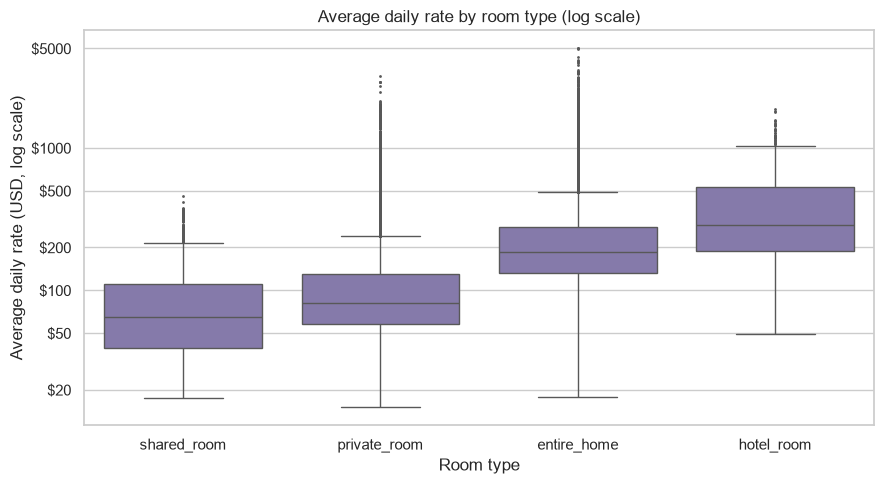

In [5]:
order = df.groupby("room_type")["avg_daily_rate"].median().sort_values().index.tolist()
summary = df.groupby("room_type").agg(records=("avg_daily_rate", "size"),
                                      listings=("listing_id", "nunique"),
                                      median_rate=("avg_daily_rate", "median")).loc[order].round(1)
print(summary.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="room_type", y="avg_daily_rate", order=order, color="#8172B2", fliersize=1, ax=ax)
ax.set_yscale("log")
ax.set_yticks([20, 50, 100, 200, 500, 1000, 5000])
ax.set_yticklabels(["$20", "$50", "$100", "$200", "$500", "$1000", "$5000"])
ax.set_title("Average daily rate by room type (log scale)")
ax.set_xlabel("Room type")
ax.set_ylabel("Average daily rate (USD, log scale)")
plt.tight_layout()
plt.savefig(FIG / "03_rate_by_room_type.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Missing data, outliers and listings by year
Missing values are summarised for the columns that contain any. Outliers are identified with the IQR rule on the log scale (appropriate for right-skewed rates) and are only described, not removed. Listings per year describe the dataset's coverage, not the market.

In [6]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False).to_frame("missing")
miss["percent"] = (100 * miss["missing"] / len(df)).round(2)
print("Columns with missing values:", len(miss), "of", df.shape[1])
print(miss.to_string())

Columns with missing values: 9 of 31
                       missing  percent
booking_lead_time_avg   133644    89.08
length_of_stay_avg      133644    89.08
booked_rate_avg          77152    51.42
bedrooms                 34154    22.76
neighborhood               923     0.62
nta2020                    100     0.07
ntaname                    100     0.07
ntatype                    100     0.07
boroname                   100     0.07


In [7]:
lr = np.log10(df["avg_daily_rate"])
q1, q3 = lr.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = 10 ** (q1 - 1.5 * iqr), 10 ** (q3 + 1.5 * iqr)
print(f"IQR-rule fences on log scale: ${low:.0f} to ${high:.0f}")

above = df["avg_daily_rate"] > high
below = df["avg_daily_rate"] < low
print("Records above upper fence:", int(above.sum()), f"({100*above.mean():.1f}%) | listings:", df.loc[above, "listing_id"].nunique())
print("Records below lower fence:", int(below.sum()), f"({100*below.mean():.1f}%) | listings:", df.loc[below, "listing_id"].nunique())
print()
print("Share of records above the upper fence, by room type:")
print((100 * above.groupby(df["room_type"]).mean()).round(1).to_string())

IQR-rule fences on log scale: $19 to $1005
Records above upper fence: 1238 (0.8%) | listings: 80
Records below lower fence: 30 (0.0%) | listings: 5

Share of records above the upper fence, by room type:
room_type
entire_home     1.1
hotel_room      5.4
private_room    0.4
shared_room     0.0


      records  listings  months
year                           
2021    25050      2505      10
2022    34466      3555      12
2023    37311      3193      12
2024    27006      3526      12
2025    22951      2114      12
2026     3250      1625       2


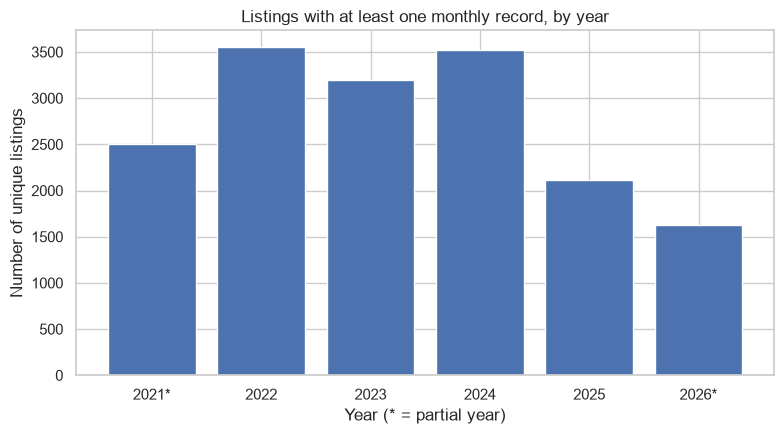

In [8]:
yr = df.groupby("year").agg(records=("listing_id", "size"),
                            listings=("listing_id", "nunique"),
                            months=("month", "nunique"))
print(yr.to_string())

labels = [f"{y}*" if m < 12 else str(y) for y, m in zip(yr.index, yr["months"])]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(labels, yr["listings"], color="#4C72B0")
ax.set_title("Listings with at least one monthly record, by year")
ax.set_xlabel("Year (* = partial year)")
ax.set_ylabel("Number of unique listings")
plt.tight_layout()
plt.savefig(FIG / "03_listings_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary
- `avg_daily_rate` is strongly right-skewed (skewness 5.42): median $140.60, mean $188.27, 95th percentile $476, maximum $4,983. On a log scale it is approximately symmetric. The median is used as the primary measure.
- Listings per residential NTA are very uneven: 4,221 listings across 191 of 197 residential NTAs (median 9, range 1 to 164). Medians per NTA are 49.5 (Manhattan), 17 (Brooklyn), 8.5 (Queens), 3 (Bronx) and 2.5 (Staten Island).
- Median rates differ by room type: shared room $65.1, private room $80.6, entire home $184.5, hotel room $288.2 (hotel and shared rooms have only 28 and 64 listings).
- Fields used in the main analysis have no missing values. Lead time and length of stay are missing in 89.08% of records; `booked_rate_avg` in 51.42%.
- By the IQR rule on the log scale (fences $19 and $1,005), 1,238 records (0.8%, 80 listings) are high outliers and 30 records (5 listings) are low outliers. None were removed.
- Listings with records per year: 3,555 (2022), 3,193 (2023), 3,526 (2024), 2,114 (2025).

## Limitations / observations
- Neighbourhood coverage is thin in the Bronx and Staten Island, so medians there are less reliable.
- Neighbourhood differences may partly reflect room-type mix.
- The set of listings differs by year, so year-to-year changes may partly reflect composition changes; yearly counts describe the dataset, not the market.